In [1]:
from toymd.potentials import *
from toymd import Trajectory1D

In [2]:
pot2 = create_potential("Harmonic", k=0.1, x0=0.0)

In [3]:
pot3 = create_potential("AsimmetricDoublewell", a=0.05, b=6.5, c=3.0)


In [4]:
traj = Trajectory1D(potential=pot3, m=1.0, dt=0.02, steps=1000, x0=2.0, v0=0.0, integrator="langevin", gamma=0.1, kT=20.0)

In [5]:
traj.run()

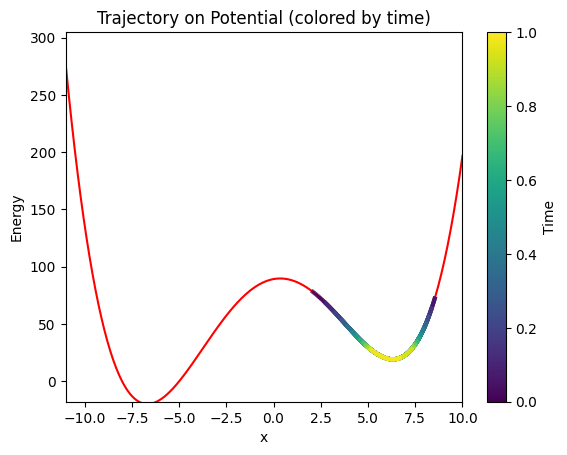

In [6]:
traj.plot_on_potential(xmin=-11, xmax=10)

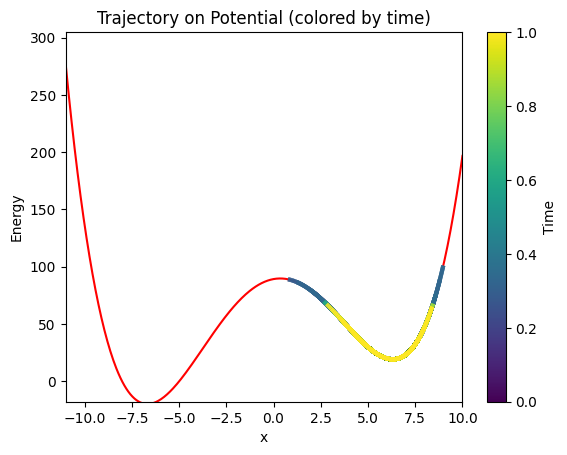

In [292]:
traj.run()
traj.plot_on_potential(xmin=-11, xmax=10)

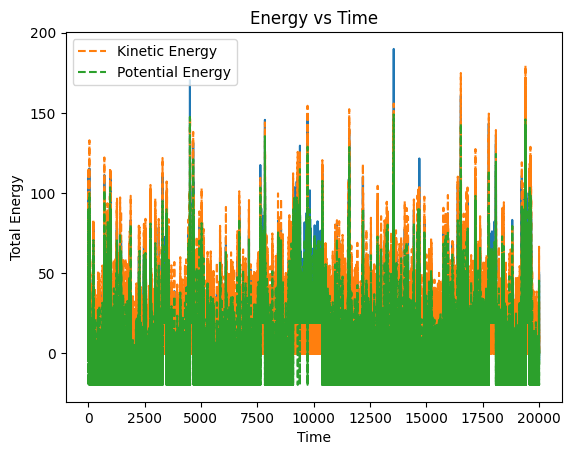

In [288]:
traj.plot_energy()

In [13]:
traj.animate_on_potential(xmin=-10, xmax=10, interval=80)

Animation size has reached 20994319 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


Omega analytic: 15.707963267948966
Omega sampled: 15.707958686259527
Relative error (%): -2.9167940874030505e-05
S_analytic, S_sample: 2.7541677982835004 2.754167506604049


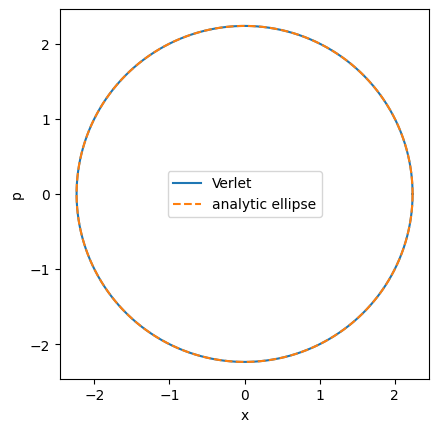

In [19]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters (dimensionless)
m = 1.0
k = 1.0
omega = np.sqrt(k/m)
kB = 1.0
h = 1.0

E = 2.5
A = np.sqrt(2*E/k)

dt = 1e-3
T = 2*np.pi/omega
n_periods = 5
nsteps = int(n_periods * T / dt)
xs = np.zeros(nsteps)
vs = np.zeros(nsteps)

x = A
v = 0.0

def accel(x): return - (k/m) * x

for i in range(nsteps):
    a = accel(x)
    x_new = x + v*dt + 0.5*a*dt*dt
    a_new = accel(x_new)
    v_new = v + 0.5*(a + a_new)*dt
    xs[i] = x_new
    vs[i] = v_new
    x, v = x_new, v_new

steps_per_period = int(T/dt)
start_idx = 0
end_idx = start_idx + steps_per_period
x_cycle = xs[start_idx:end_idx]
v_cycle = vs[start_idx:end_idx]
p_cycle = m * v_cycle

# Shoelace area
x_coords = x_cycle
y_coords = p_cycle
area = 0.5 * np.abs(np.dot(x_coords, np.roll(y_coords, -1)) - np.dot(y_coords, np.roll(x_coords, -1)))

Omega_analytic = 2 * np.pi * E / omega
S_sample = kB * np.log(area / h)
S_analytic = kB * np.log(Omega_analytic / h)

print("Omega analytic:", Omega_analytic)
print("Omega sampled:", area)
print("Relative error (%):", (area - Omega_analytic)/Omega_analytic * 100)
print("S_analytic, S_sample:", S_analytic, S_sample)

# Plot
plt.figure()
plt.plot(x_cycle, p_cycle, label='Verlet')
thetas = np.linspace(0,2*np.pi,400)
x_ell = A * np.cos(thetas)
p_ell = - m * omega * A * np.sin(thetas)
plt.plot(x_ell, p_ell, '--', label='analytic ellipse')
plt.gca().set_aspect('equal', 'box')
plt.xlabel('x'); plt.ylabel('p'); plt.legend(); plt.show()
